# Gait-phase TCN ensemble

Can disagreement between gait-phase predictors flag unfamiliar movement?

Read top-to-bottom: setup → equations → architecture → training → figures → LOTO → interpretation.
**Safe default:** saved-result exploration only; training is disabled.

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'ml/vanilla/registry.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Launch Jupyter within this repository.')
sys.path.insert(0, str(ROOT / 'notebooks/model_exploration'))
get_ipython().run_line_magic('matplotlib', 'inline')
from _exploration import *
import torch
from dataclasses import asdict
torch.set_num_threads(2)  # small architecture checks; training CLI runs separately
torch.manual_seed(0)
RUN_TRAINING = False
print('Repository:', ROOT)
print('Kernel:', sys.executable)

Repository: /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton
Kernel: /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/.venv/bin/python


In [2]:
KEY = 'ensemble'
RUN = ROOT / RUNS[KEY]
inventory(RUN)

**Artifact directory:** `ml/vanilla/runs/ensemble_gp`

,artifact,available
0,report.json,True
1,final.pt,True
2,eval_test.json,True
3,figures,True


## Data and evaluation contract

- Input: **16 channels × 200 samples**, one second at 200 Hz; stored window stride 10 samples.
- Original ID tasks: level ground (LG), ramp ascent (RA), ramp descent (RD).
  Original pseudo-OOD tasks: stair ascent (SA), stair descent (SD), standing (ST), transitions (TR).
- Participants: 12 train / 4 validation / 4 test. Task availability differs by participant.
  Input scaling is fitted on training data, never refitted on test data.
- Scoring does **not** predict a task label. High $\Psi$ means more anomalous.

$$\widetilde\Psi_t=\operatorname{median}(\Psi_{t-9},\ldots,\Psi_t),\qquad
\tau=Q_{0.995}(\widetilde\Psi_{\mathrm{train,ID}}),\qquad
\widehat o_t=\mathbf1[\widetilde\Psi_t>\tau].$$

Filtering restarts for each trial; early windows use the available history. The ten-score
filter corresponds to the repository's nominal 0.5 s smoothing setting, **not** ten raw samples.

$$\mathrm{recall}=\frac{TP}{TP+FN},\quad
\mathrm{specificity}=\frac{TN}{TN+FP},\quad J=\mathrm{recall}+\mathrm{specificity}-1.$$

AUROC measures ranking across thresholds; it is **not the fraction of OOD detected**.
OOD is the positive class. Tables below show J on −1 to 1, although source JSON stores 100J.
Scores and thresholds are not calibrated probabilities of being unsafe.

## Model and mathematics

The target is bilateral sine-transformed gait phase, not a moving/stationary class:
 $$y_d(t)=\sin(2\pi\phi_d(t)),\qquad \phi_d\in[0,1).$$
 The output head is tanh. Missing leg labels are masked; windows require at least one valid label.
 Each branch has three causal Conv1d → BatchNorm → ReLU blocks, 30 filters, kernel 20,
 dilations (1,2,8). Its theoretical receptive field is
 $$R=1+(20-1)(1+2+8)=210\text{ samples},$$
 covering the available 200-sample window (with left padding).

For branch $m$ and target dimension $d$, train with masked mean squared error:

$$\mathcal L=\frac{\sum_{n,m,d}a_{nd}(f_{md}(x_n)-y_{nd})^2}
{M\sum_{n,d}a_{nd}},\qquad M=7.$$

$a$ is the target-validity mask. The online score uses no target labels:

$$\bar f_d(x)=\frac1M\sum_m f_{md}(x),\qquad
\Psi(x)=\frac1D\sum_d\frac1M\sum_m(f_{md}(x)-\bar f_d(x))^2.$$

This is population variance across branches, not sample variance. Agreement is a candidate
uncertainty signal, **not a guarantee that an input is familiar or a prediction is correct**.

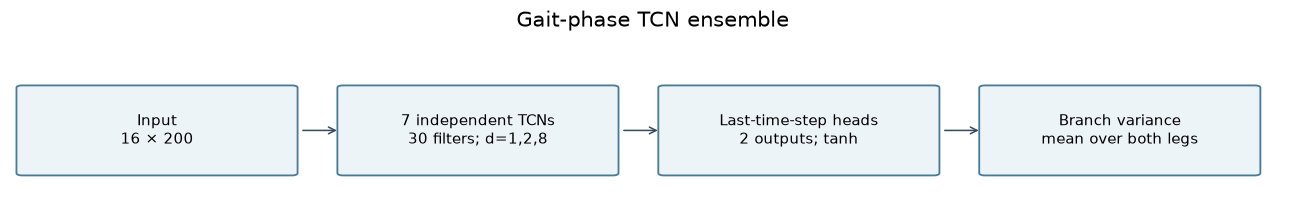

In [3]:
diagram([['Input\n16 × 200', '7 independent TCNs\n30 filters; d=1,2,8', 'Last-time-step heads\n2 outputs; tanh', 'Branch variance\nmean over both legs']], 'Gait-phase TCN ensemble')

### Executable architecture check

This constructs **fresh random weights** and checks shapes only. The saved figures later come from trained runs; this dummy forward pass does not.

In [4]:
from models.ensemble import create_ensemble
model = create_ensemble(16, 2)
example = torch.zeros(2, 16, 200)
output = model_shapes(model, example)

GaitPhaseEnsemble: 321,524 parameters
Input: (2, 16, 200)   Outputs: [(2, 7, 2)]
Layer table shows one representative branch; weights are not shared.


,module,class,direct parameters
0,network.0.conv,CausalConv1d,9630
1,network.0.norm,BatchNorm1d,60
2,network.0.relu,ReLU,0
3,network.1.conv,CausalConv1d,18030
4,network.1.norm,BatchNorm1d,60
5,network.1.relu,ReLU,0
6,network.2.conv,CausalConv1d,18030
7,network.2.norm,BatchNorm1d,60
8,network.2.relu,ReLU,0
9,fc,Linear,62


## Training


Twelve leave-one-subject-out (LOSO) folds over the training participants select the final
epoch count from held-out-subject loss. A freshly initialized ensemble then trains on all
training participants for that duration. Defaults: Adam, learning rate 0.001, batch 1024,
maximum 60 fold epochs, patience 10. The report below is authoritative for a saved run.
Branches have independent weights/initialization but see the same training batches.

In [5]:
from registry import get
config_class = get(KEY).config()
display(pd.Series(asdict(config_class()), name='current default').to_frame())

,current default
lr,0.001
batch_size,1024
max_epochs,60
patience,10
seed,0
device,None
threshold_percentile,99.5
n_members,7
out_dir,ml/vanilla/runs
loso_folds,None


### Saved training configuration and learning curves

Current defaults can differ from a past run. Below we read the report; missing reports remain explicitly missing. Loss scales from different objectives are not directly comparable.

,saved value
lr,0.001
batch_size,1024
max_epochs,60
patience,10
seed,0
device,None
threshold_percentile,99.5
n_members,7
out_dir,ml/vanilla/runs/paper
loso_folds,None


,saved result
threshold,0.001817
val_loss,0.011549
LOSO selected epochs,17.000000


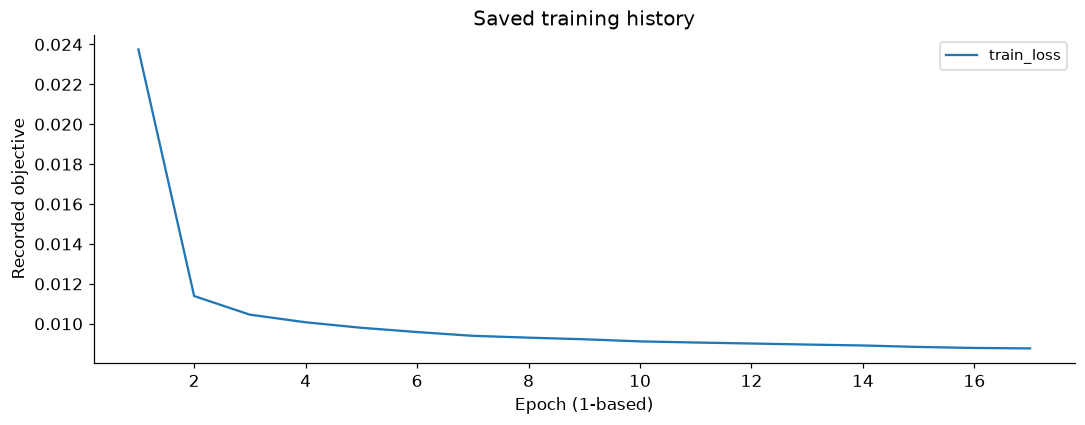

,epoch,train_loss,seconds
12,12,0.008957,91.4
13,13,0.008911,91.1
14,14,0.008837,91.1
15,15,0.008787,90.8
16,16,0.008764,91.5


**LOSO summary (epoch selection, not LOTO):**

{'n_epochs': 17,
 'folds': [{'subject': 'AB15',
   'best_epoch': 13,
   'val_loss': 0.010134470873935991,
   'epochs_run': 24},
  {'subject': 'AB17',
   'best_epoch': 23,
   'val_loss': 0.009798009181825969,
   'epochs_run': 34},
  {'subject': 'AB18',
   'best_epoch': 14,
   'val_loss': 0.010044739761515582,
   'epochs_run': 25},
  {'subject': 'AB19',
   'best_epoch': 9,
   'val_loss': 0.015213818738863778,
   'epochs_run': 20},
  {'subject': 'AB21',
   'best_epoch': 22,
   'val_loss': 0.008409133527371635,
   'epochs_run': 33},
  {'subject': 'AB23',
   'best_epoch': 30,
   'val_loss': 0.009213207238167608,
   'epochs_run': 41},
  {'subject': 'AB25',
   'best_epoch': 26,
   'val_loss': 0.0202787143988108,
   'epochs_run': 37},
  {'subject': 'AB26',
   'best_epoch': 16,
   'val_loss': 0.011368780093404276,
   'epochs_run': 27},
  {'subject': 'AB27',
   'best_epoch': 11,
   'val_loss': 0.012356615386340681,
   'epochs_run': 22},
  {'subject': 'AB28',
   'best_epoch': 7,
   'val_loss': 0.

In [6]:
config_and_history(RUN)

### Optional: run the real training pipeline

This can take hours. The commands use this kernel’s Python and write to a **new** directory. Set `RUN_TRAINING=True` in the setup cell only when ready. Existing runs are protected. After completion, set `RUN = NEW_RUN` and rerun the result cells.

In [7]:
NEW_RUN = ROOT / 'notebooks/model_exploration/runs' / KEY
commands = training_commands(KEY, NEW_RUN)
run_commands(commands, NEW_RUN, enabled=RUN_TRAINING)

/Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/.venv/bin/python /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/ml/vanilla/main.py all --model ensemble --out /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/notebooks/model_exploration/runs/ensemble

Preview only. Set RUN_TRAINING=True explicitly to run.


## Saved test results

These values come directly from `eval_test.json`. An optimized test-ROC threshold, where reported, is diagnostic—not a validated operating point.

In [8]:
results_table(RUN)

,AUROC,recall (%),specificity (%),J (−1 to 1),threshold
score,,,,,
primary,0.8587,39.4046,98.1394,0.3754,0.0018


,mode,kind,windows,flagged_%,median_psi
0,LG,ID,26753,1.7792,0.0003
1,RA,ID,17354,0.4668,0.0005
2,RD,ID,13938,3.7523,0.0005
3,SA,OOD,10273,6.6388,0.0007
4,SD,OOD,10155,66.7848,0.0027
5,ST,OOD,621,100.0000,0.0144
6,TR,OOD,1994,49.8997,0.0018


## Model behavior through figures

Images are embedded from the existing run, without rewriting it. Captions explain what each figure can and cannot establish.

**psi_by_task.png** — Score distributions by task. The threshold is an operating point, not an ID/OOD boundary guaranteed by the model.

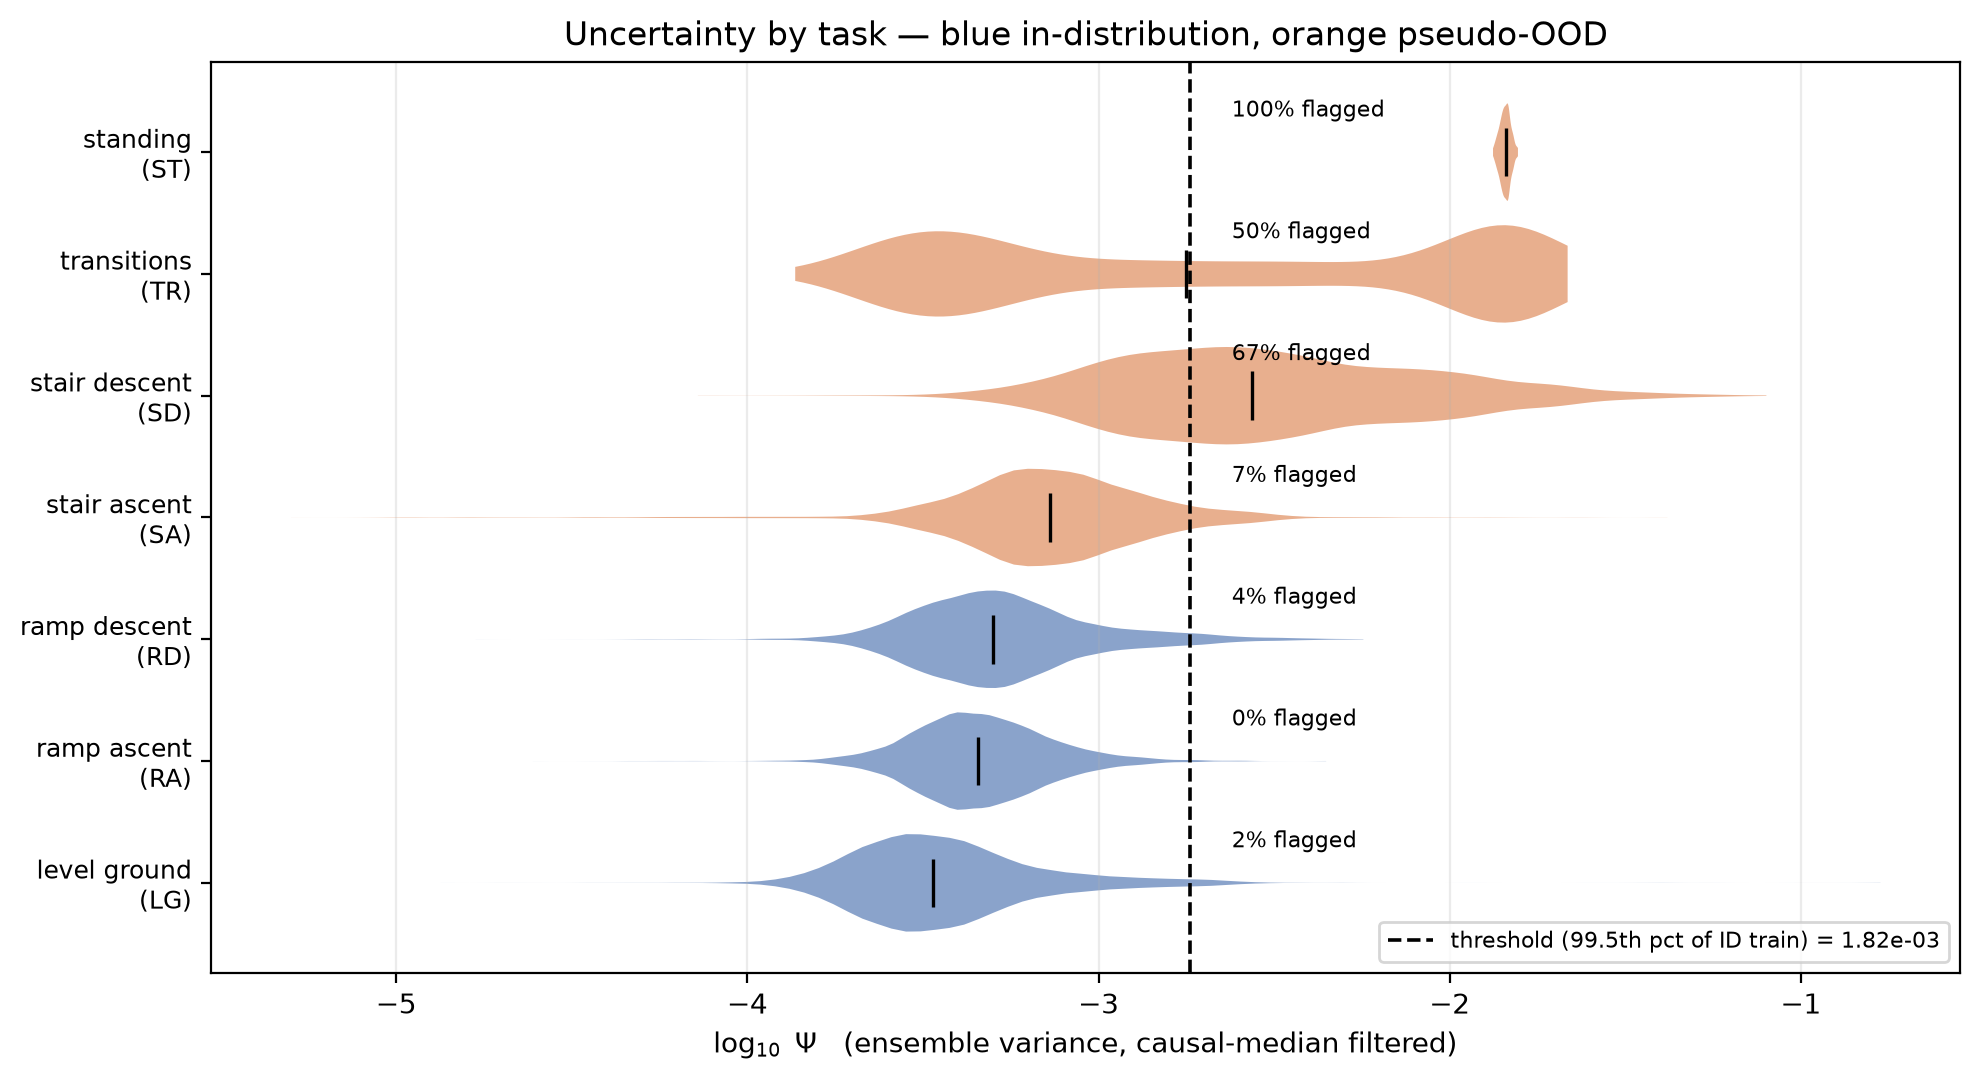

**roc.png** — Threshold sweep: ranking quality, not the fraction detected at the saved threshold.

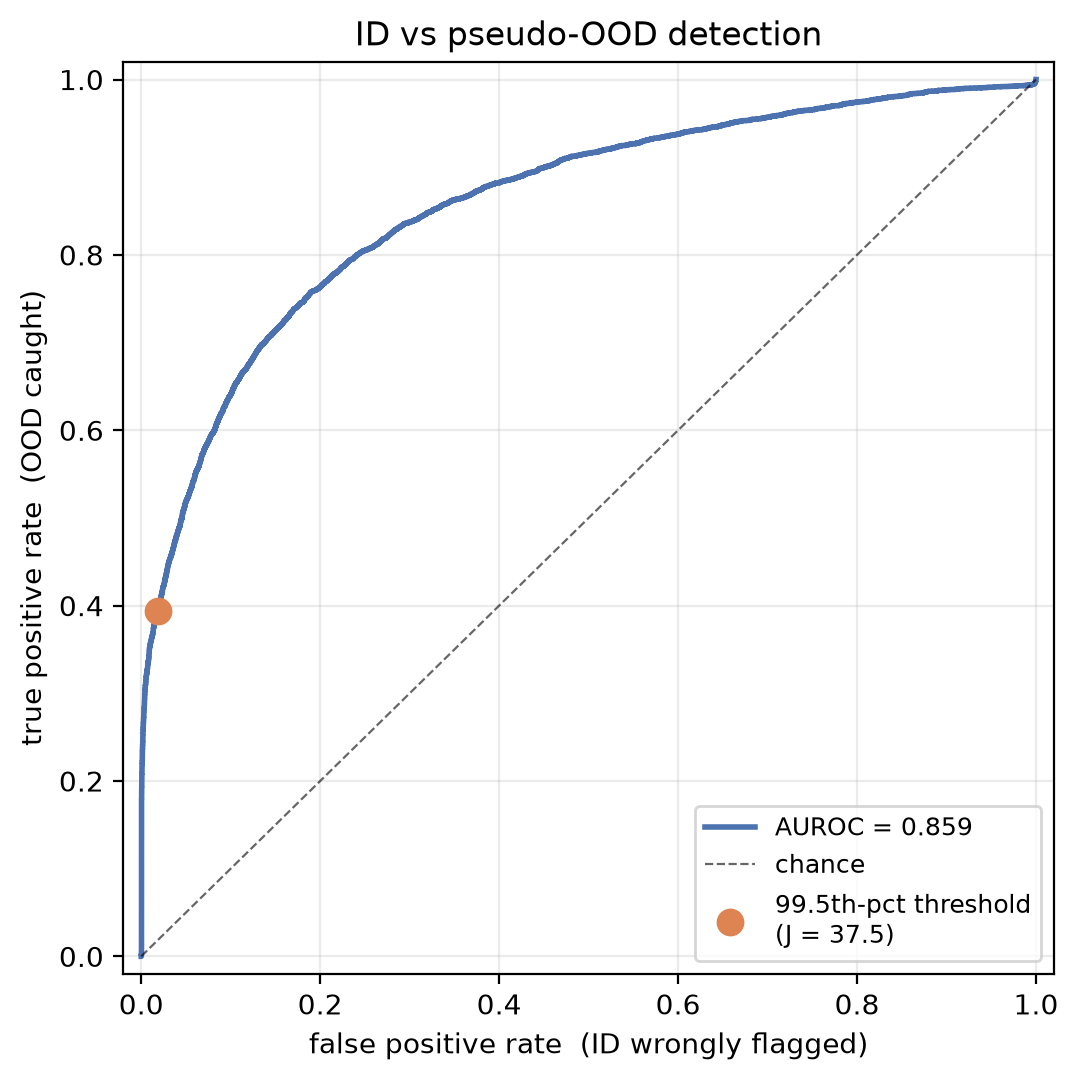

**detection_by_task.png** — Actual flag rates at the saved training threshold; flags on ID tasks are false alarms.

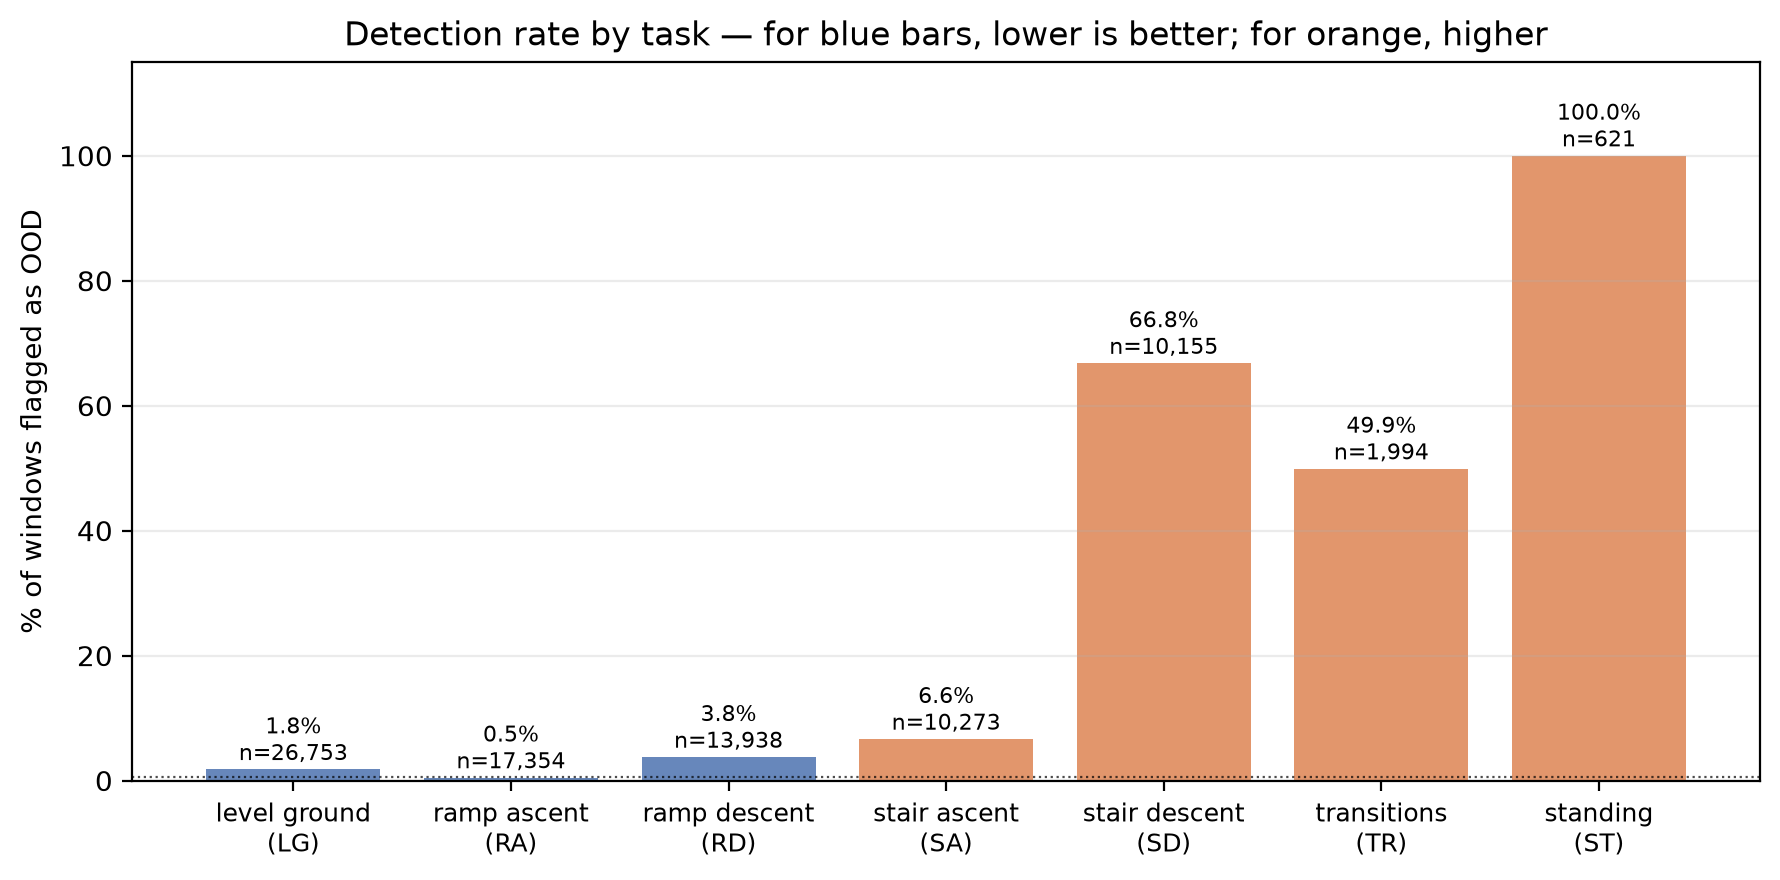

**loso.png** — Training duration selection across held-out training participants; this is LOSO, not task holdout.

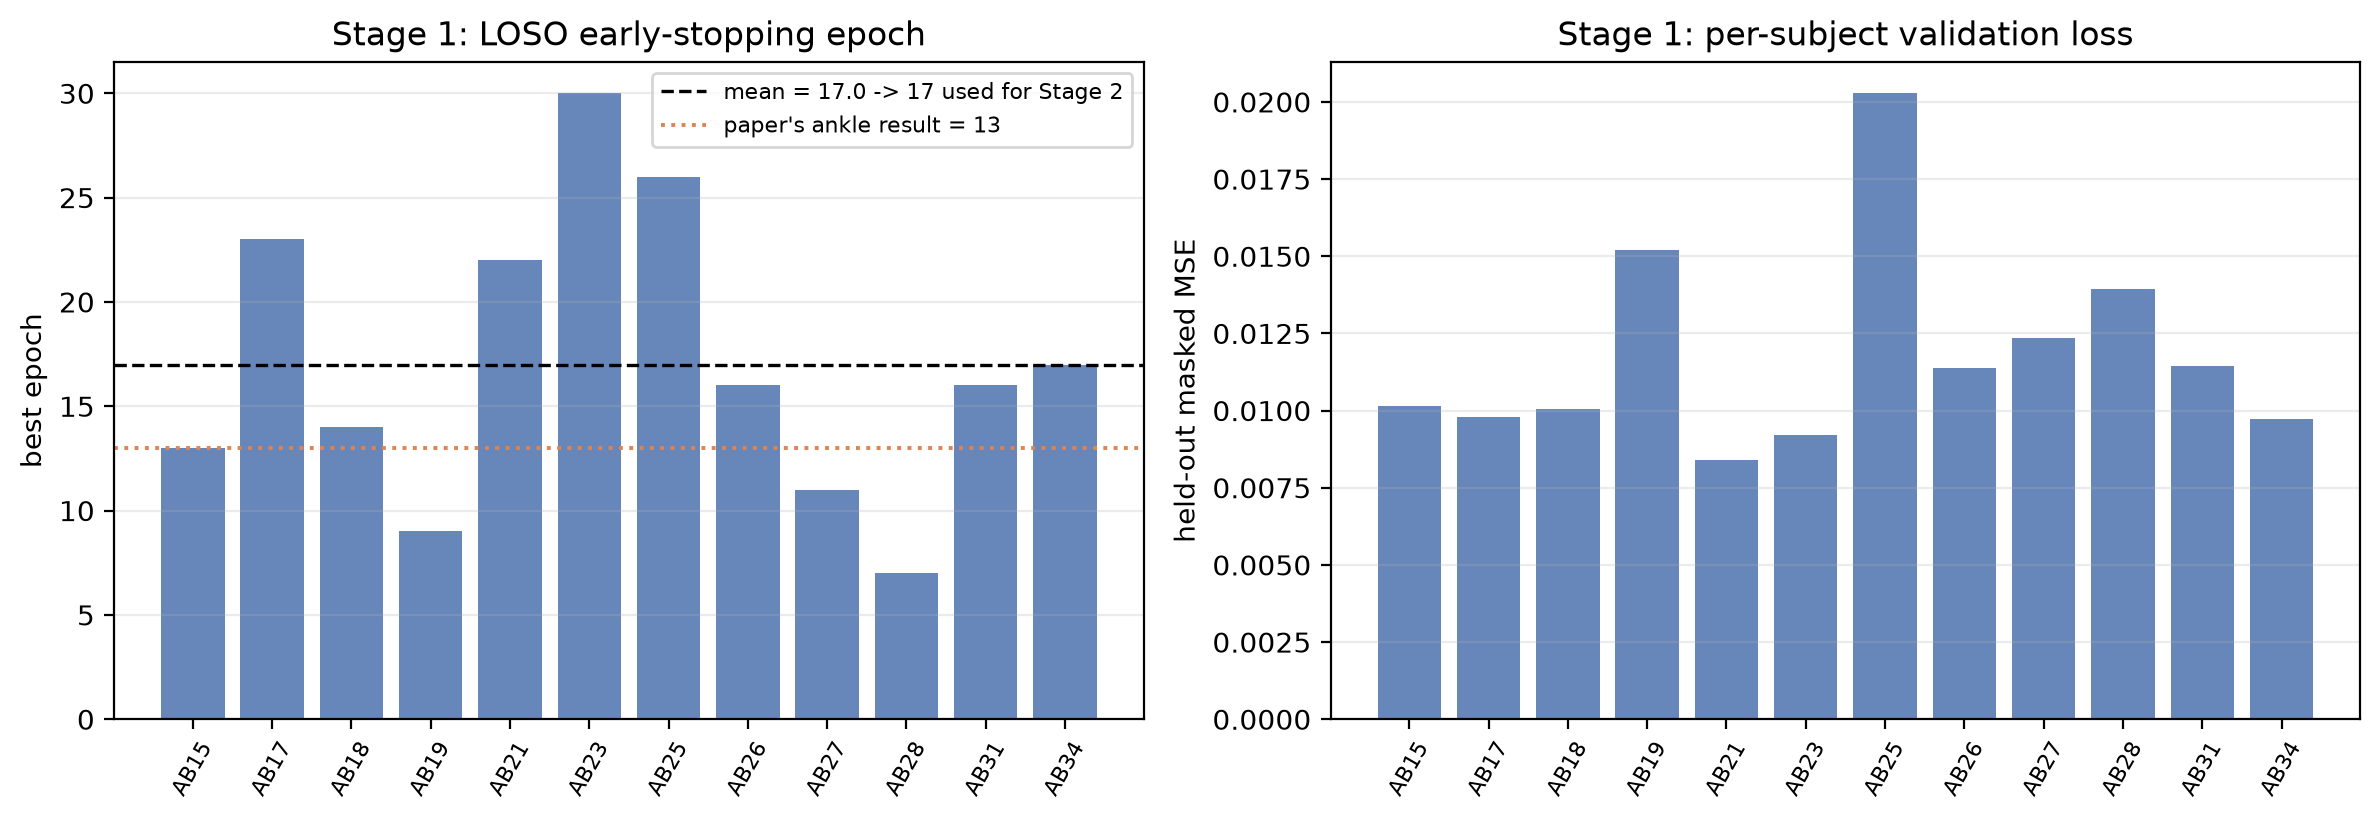

In [9]:
gallery(RUN, [('psi_by_task.png', 'Score distributions by task. The threshold is an operating point, not an ID/OOD boundary guaranteed by the model.'), ('roc.png', 'Threshold sweep: ranking quality, not the fraction detected at the saved threshold.'), ('detection_by_task.png', 'Actual flag rates at the saved training threshold; flags on ID tasks are false alarms.'), ('loso.png', 'Training duration selection across held-out training participants; this is LOSO, not task holdout.')])

## Leave-one-task-out (LOTO) stress test

SA: stair ascent; ST: standing; TR: transitions. Each run excludes the named task from **all training participants**, trains on the other six, and tests on held-out participants. This differs from LOSO epoch selection.

Standing test data come from one trial of one participant: 621 overlapping windows, or 600 for the gait-phase subset. Gait-phase LOTO uses fewer labelled windows overall. Raw window counts are not independent repetitions; cross-run changes do not isolate a causal training effect.

,held out,score,AUROC,recall (%),ID false alarms (%),J,OOD windows
0,SA,primary,0.6981,0.5287,2.3548,-0.0183,6053
1,ST,primary,0.2357,0.0000,2.0995,-0.0210,600
2,TR,primary,0.6069,0.7941,1.3255,-0.0053,1889


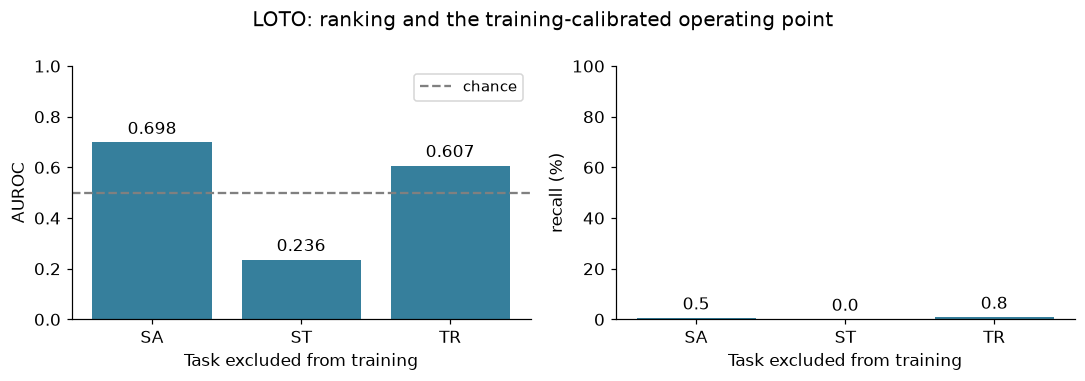

In [10]:
loto_results(KEY)

## Takeaway and next checks

Low disagreement on standing does not prove correct gait-phase prediction. In LOTO, all branches can agree on an unseen input. Inspect prediction errors separately; gait-phase labels also restrict which windows enter this model.

Keep score/threshold selection on validation data. Report both ranking and recall at a declared false-alarm budget, repeat seeds, and quantify participant/trial-level variation before making robustness claims.

In [11]:
source_links(['ml/vanilla/models/ensemble.py', 'ml/vanilla/training/ensemble.py', 'ml/vanilla/evaluation/ensemble.py'])

Implementation sources: [ensemble.py](../../ml/vanilla/models/ensemble.py), [ensemble.py](../../ml/vanilla/training/ensemble.py), [ensemble.py](../../ml/vanilla/evaluation/ensemble.py)